In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/brianleung2020/eeg-motor-movementimagery-dataset/files/64_channel_sharbrough-old.png
/kaggle/input/datasets/brianleung2020/eeg-motor-movementimagery-dataset/files/64_channel_sharbrough.pdf
/kaggle/input/datasets/brianleung2020/eeg-motor-movementimagery-dataset/files/64_channel_sharbrough.png
/kaggle/input/datasets/brianleung2020/eeg-motor-movementimagery-dataset/files/ANNOTATORS
/kaggle/input/datasets/brianleung2020/eeg-motor-movementimagery-dataset/files/RECORDS
/kaggle/input/datasets/brianleung2020/eeg-motor-movementimagery-dataset/files/SHA256SUMS.txt
/kaggle/input/datasets/brianleung2020/eeg-motor-movementimagery-dataset/files/wfdbcal
/kaggle/input/datasets/brianleung2020/eeg-motor-movementimagery-dataset/files/S001/S001R01.edf
/kaggle/input/datasets/brianleung2020/eeg-motor-movementimagery-dataset/files/S001/S001R01.edf.event
/kaggle/input/datasets/brianleung2020/eeg-motor-movementimagery-dataset/files/S001/S001R02.edf
/kaggle/input/datasets/brianleung2020/e

In [3]:
import mne

In [4]:
data_dir="/kaggle/input/datasets/brianleung2020/eeg-motor-movementimagery-dataset/files"

In [5]:
print(len(os.listdir(data_dir)))

116


In [6]:
print(os.listdir(data_dir)[:20])

['64_channel_sharbrough-old.png', '64_channel_sharbrough.pdf', '64_channel_sharbrough.png', 'ANNOTATORS', 'RECORDS', 'S001', 'S002', 'S003', 'S004', 'S005', 'S006', 'S007', 'S008', 'S009', 'S010', 'S011', 'S012', 'S013', 'S014', 'S015']


In [7]:
for vals in os.listdir(data_dir):
    folder_path=os.path.join(data_dir,vals)
    if os.path.isdir(folder_path):
        print(os.listdir(folder_path))
        print("-"*20)

['S001R01.edf', 'S001R01.edf.event', 'S001R02.edf', 'S001R02.edf.event', 'S001R03.edf', 'S001R03.edf.event', 'S001R04.edf', 'S001R04.edf.event', 'S001R05.edf', 'S001R05.edf.event', 'S001R06.edf', 'S001R06.edf.event', 'S001R07.edf', 'S001R07.edf.event', 'S001R08.edf', 'S001R08.edf.event', 'S001R09.edf', 'S001R09.edf.event', 'S001R10.edf', 'S001R10.edf.event', 'S001R11.edf', 'S001R11.edf.event', 'S001R12.edf', 'S001R12.edf.event', 'S001R13.edf', 'S001R13.edf.event', 'S001R14.edf', 'S001R14.edf.event']
--------------------
['S002R01.edf', 'S002R01.edf.event', 'S002R02.edf', 'S002R02.edf.event', 'S002R03.edf', 'S002R03.edf.event', 'S002R04.edf', 'S002R04.edf.event', 'S002R05.edf', 'S002R05.edf.event', 'S002R06.edf', 'S002R06.edf.event', 'S002R07.edf', 'S002R07.edf.event', 'S002R08.edf', 'S002R08.edf.event', 'S002R09.edf', 'S002R09.edf.event', 'S002R10.edf', 'S002R10.edf.event', 'S002R11.edf', 'S002R11.edf.event', 'S002R12.edf', 'S002R12.edf.event', 'S002R13.edf', 'S002R13.edf.event', 'S002

In [8]:
os.listdir(data_dir)[5:]

['S001',
 'S002',
 'S003',
 'S004',
 'S005',
 'S006',
 'S007',
 'S008',
 'S009',
 'S010',
 'S011',
 'S012',
 'S013',
 'S014',
 'S015',
 'S016',
 'S017',
 'S018',
 'S019',
 'S020',
 'S021',
 'S022',
 'S023',
 'S024',
 'S025',
 'S026',
 'S027',
 'S028',
 'S029',
 'S030',
 'S031',
 'S032',
 'S033',
 'S034',
 'S035',
 'S036',
 'S037',
 'S038',
 'S039',
 'S040',
 'S041',
 'S042',
 'S043',
 'S044',
 'S045',
 'S046',
 'S047',
 'S048',
 'S049',
 'S050',
 'S051',
 'S052',
 'S053',
 'S054',
 'S055',
 'S056',
 'S057',
 'S058',
 'S059',
 'S060',
 'S061',
 'S062',
 'S063',
 'S064',
 'S065',
 'S066',
 'S067',
 'S068',
 'S069',
 'S070',
 'S071',
 'S072',
 'S073',
 'S074',
 'S075',
 'S076',
 'S077',
 'S078',
 'S079',
 'S080',
 'S081',
 'S082',
 'S083',
 'S084',
 'S085',
 'S086',
 'S087',
 'S088',
 'S089',
 'S090',
 'S091',
 'S092',
 'S093',
 'S094',
 'S095',
 'S096',
 'S097',
 'S098',
 'S099',
 'S100',
 'S101',
 'S102',
 'S103',
 'S104',
 'S105',
 'S106',
 'S107',
 'S108',
 'S109',
 'SHA256SUMS.txt',


In [9]:
sampler=os.listdir(data_dir)[5:]
sample=os.path.join(data_dir,sampler[0])
for values in os.listdir(sample):
    # print(values)
    if "R04" in values:
        print(values)

S001R04.edf
S001R04.edf.event


In [10]:
event_path=os.path.join(sample,"S001R04.edf.event")

In [11]:
event_path

'/kaggle/input/datasets/brianleung2020/eeg-motor-movementimagery-dataset/files/S001/S001R04.edf.event'

In [12]:
with open(event_path,"rb") as f:
    for i in range(10):
        line=f.readline()
        if not line:
            break
        print(repr(line))

b'\x00X\x17\xfc## time resolution: 160\x00\x00\xec\xff\xff\xff\xff\x01\x00\x00X\x10\xfcT0 duration: 4.2\xa0Z\x10\xfcT2 duration: 4.1\x90Z\x10\xfcT0 duration: 4.2\xa0Z\x10\xfcT1 duration: 4.1\x90Z\x10\xfcT0 duration: 4.2\xa0Z\x10\xfcT1 duration: 4.1\x90Z\x10\xfcT0 duration: 4.2\xa0Z\x10\xfcT2 duration: 4.1\x90Z\x10\xfcT0 duration: 4.2\xa0Z\x10\xfcT2 duration: 4.1\x90Z\x10\xfcT0 duration: 4.2\xa0Z\x10\xfcT1 duration: 4.1\x90Z\x10\xfcT0 duration: 4.2\xa0Z\x10\xfcT2 duration: 4.1\x90Z\x10\xfcT0 duration: 4.2\xa0Z\x10\xfcT1 duration: 4.1\x90Z\x10\xfcT0 duration: 4.2\xa0Z\x10\xfcT2 duration: 4.1\x90Z\x10\xfcT0 duration: 4.2\xa0Z\x10\xfcT1 duration: 4.1\x90Z\x10\xfcT0 duration: 4.2\xa0Z\x10\xfcT1 duration: 4.1\x90Z\x10\xfcT0 duration: 4.2\xa0Z\x10\xfcT2 duration: 4.1\x90Z\x10\xfcT0 duration: 4.2\xa0Z\x10\xfcT1 duration: 4.1\x90Z\x10\xfcT0 duration: 4.2\xa0Z\x10\xfcT2 duration: 4.1\x90Z\x10\xfcT0 duration: 4.2\xa0Z\x10\xfcT1 duration: 4.1\x00\x00'


In [13]:
edf_path=os.path.join(sample,"S001R04.edf")
raw=mne.io.read_raw_edf(
    edf_path,
    preload=False,
    verbose=False
)


In [14]:
print(raw.info)

<Info | 8 non-empty values
 bads: []
 ch_names: Fc5., Fc3., Fc1., Fcz., Fc2., Fc4., Fc6., C5.., C3.., C1.., ...
 chs: 64 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 80.0 Hz
 meas_date: 2009-08-12 16:15:00 UTC
 nchan: 64
 projs: []
 sfreq: 160.0 Hz
 subject_info: <subject_info | his_id: X, sex: 0, last_name: X>
>


In [15]:
print("Sampling Frequency",raw.info['sfreq'])
print("Channel names:", raw.ch_names)
print("Annotations:")
print(raw.annotations)

Sampling Frequency 160.0
Channel names: ['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..', 'Cz..', 'C2..', 'C4..', 'C6..', 'Cp5.', 'Cp3.', 'Cp1.', 'Cpz.', 'Cp2.', 'Cp4.', 'Cp6.', 'Fp1.', 'Fpz.', 'Fp2.', 'Af7.', 'Af3.', 'Afz.', 'Af4.', 'Af8.', 'F7..', 'F5..', 'F3..', 'F1..', 'Fz..', 'F2..', 'F4..', 'F6..', 'F8..', 'Ft7.', 'Ft8.', 'T7..', 'T8..', 'T9..', 'T10.', 'Tp7.', 'Tp8.', 'P7..', 'P5..', 'P3..', 'P1..', 'Pz..', 'P2..', 'P4..', 'P6..', 'P8..', 'Po7.', 'Po3.', 'Poz.', 'Po4.', 'Po8.', 'O1..', 'Oz..', 'O2..', 'Iz..']
Annotations:
<Annotations | 30 segments: T0 (15), T1 (8), T2 (7)>


In [16]:
for onset, duration, description in zip(
    raw.annotations.onset,
    raw.annotations.duration,
    raw.annotations.description
):
    print(
        f"Start: {onset:.2f}s | "
        f"Duration: {duration:.2f}s | "
        f"Label: {description}"
    )

Start: 0.00s | Duration: 4.20s | Label: T0
Start: 4.20s | Duration: 4.10s | Label: T2
Start: 8.30s | Duration: 4.20s | Label: T0
Start: 12.50s | Duration: 4.10s | Label: T1
Start: 16.60s | Duration: 4.20s | Label: T0
Start: 20.80s | Duration: 4.10s | Label: T1
Start: 24.90s | Duration: 4.20s | Label: T0
Start: 29.10s | Duration: 4.10s | Label: T2
Start: 33.20s | Duration: 4.20s | Label: T0
Start: 37.40s | Duration: 4.10s | Label: T2
Start: 41.50s | Duration: 4.20s | Label: T0
Start: 45.70s | Duration: 4.10s | Label: T1
Start: 49.80s | Duration: 4.20s | Label: T0
Start: 54.00s | Duration: 4.10s | Label: T2
Start: 58.10s | Duration: 4.20s | Label: T0
Start: 62.30s | Duration: 4.10s | Label: T1
Start: 66.40s | Duration: 4.20s | Label: T0
Start: 70.60s | Duration: 4.10s | Label: T2
Start: 74.70s | Duration: 4.20s | Label: T0
Start: 78.90s | Duration: 4.10s | Label: T1
Start: 83.00s | Duration: 4.20s | Label: T0
Start: 87.20s | Duration: 4.10s | Label: T1
Start: 91.30s | Duration: 4.20s | L

In [17]:
# events=mne.find_events(raw)
events,events_id=mne.events_from_annotations(raw)

Used Annotations descriptions: ['T0', 'T1', 'T2']


In [18]:
events_id

{'T0': 1, 'T1': 2, 'T2': 3}

In [19]:
len(events)

30

In [20]:
print(raw.get_channel_types())
print(raw.ch_names[:15])

['eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg']
['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..', 'Cz..', 'C2..', 'C4..', 'C6..', 'Cp5.']


In [21]:
epochs=mne.Epochs(
    raw,
    events,
    event_id={
        "left":events_id["T1"],
        "right":events_id["T2"]
    },
    tmin=0,
    tmax=4.0,
    baseline=None,
    preload=True
)

Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Loading data for 15 events and 641 original time points ...
0 bad epochs dropped


In [22]:
print(epochs)

<Epochs | 15 events (all good), 0 – 4 s (baseline off), ~4.7 MiB, data loaded,
 'left': 8
 'right': 7>


In [23]:
print(epochs.times)

[0.      0.00625 0.0125  0.01875 0.025   0.03125 0.0375  0.04375 0.05
 0.05625 0.0625  0.06875 0.075   0.08125 0.0875  0.09375 0.1     0.10625
 0.1125  0.11875 0.125   0.13125 0.1375  0.14375 0.15    0.15625 0.1625
 0.16875 0.175   0.18125 0.1875  0.19375 0.2     0.20625 0.2125  0.21875
 0.225   0.23125 0.2375  0.24375 0.25    0.25625 0.2625  0.26875 0.275
 0.28125 0.2875  0.29375 0.3     0.30625 0.3125  0.31875 0.325   0.33125
 0.3375  0.34375 0.35    0.35625 0.3625  0.36875 0.375   0.38125 0.3875
 0.39375 0.4     0.40625 0.4125  0.41875 0.425   0.43125 0.4375  0.44375
 0.45    0.45625 0.4625  0.46875 0.475   0.48125 0.4875  0.49375 0.5
 0.50625 0.5125  0.51875 0.525   0.53125 0.5375  0.54375 0.55    0.55625
 0.5625  0.56875 0.575   0.58125 0.5875  0.59375 0.6     0.60625 0.6125
 0.61875 0.625   0.63125 0.6375  0.64375 0.65    0.65625 0.6625  0.66875
 0.675   0.68125 0.6875  0.69375 0.7     0.70625 0.7125  0.71875 0.725
 0.73125 0.7375  0.74375 0.75    0.75625 0.7625  0.76875 0.775   

In [24]:
print("Epochs:", len(epochs))
print("Channels:", len(epochs.ch_names))
print("Time points per epoch:", len(epochs.times))
print("Sampling frequency:", epochs.info["sfreq"])
print("Labels:", epochs.events[:, -1])
print("Data shape:", epochs.get_data().shape)

Epochs: 15
Channels: 64
Time points per epoch: 641
Sampling frequency: 160.0
Labels: [3 2 2 3 3 2 3 2 3 2 2 3 2 3 2]
Data shape: (15, 64, 641)


In [25]:
epochs.events

array([[  672,     0,     3],
       [ 2000,     0,     2],
       [ 3328,     0,     2],
       [ 4656,     0,     3],
       [ 5984,     0,     3],
       [ 7312,     0,     2],
       [ 8640,     0,     3],
       [ 9968,     0,     2],
       [11296,     0,     3],
       [12624,     0,     2],
       [13952,     0,     2],
       [15280,     0,     3],
       [16608,     0,     2],
       [17936,     0,     3],
       [19264,     0,     2]])

In [26]:
epochs.ch_names

['Fc5.',
 'Fc3.',
 'Fc1.',
 'Fcz.',
 'Fc2.',
 'Fc4.',
 'Fc6.',
 'C5..',
 'C3..',
 'C1..',
 'Cz..',
 'C2..',
 'C4..',
 'C6..',
 'Cp5.',
 'Cp3.',
 'Cp1.',
 'Cpz.',
 'Cp2.',
 'Cp4.',
 'Cp6.',
 'Fp1.',
 'Fpz.',
 'Fp2.',
 'Af7.',
 'Af3.',
 'Afz.',
 'Af4.',
 'Af8.',
 'F7..',
 'F5..',
 'F3..',
 'F1..',
 'Fz..',
 'F2..',
 'F4..',
 'F6..',
 'F8..',
 'Ft7.',
 'Ft8.',
 'T7..',
 'T8..',
 'T9..',
 'T10.',
 'Tp7.',
 'Tp8.',
 'P7..',
 'P5..',
 'P3..',
 'P1..',
 'Pz..',
 'P2..',
 'P4..',
 'P6..',
 'P8..',
 'Po7.',
 'Po3.',
 'Poz.',
 'Po4.',
 'Po8.',
 'O1..',
 'Oz..',
 'O2..',
 'Iz..']

In [27]:
print("Event ID mapping:", epochs.event_id)
print("Label counts:", {
    label: len(epochs[label])
    for label in epochs.event_id
})
epochs.events

Event ID mapping: {'left': 2, 'right': 3}
Label counts: {'left': 8, 'right': 7}


array([[  672,     0,     3],
       [ 2000,     0,     2],
       [ 3328,     0,     2],
       [ 4656,     0,     3],
       [ 5984,     0,     3],
       [ 7312,     0,     2],
       [ 8640,     0,     3],
       [ 9968,     0,     2],
       [11296,     0,     3],
       [12624,     0,     2],
       [13952,     0,     2],
       [15280,     0,     3],
       [16608,     0,     2],
       [17936,     0,     3],
       [19264,     0,     2]])

In [28]:
epochs_filtered=epochs.copy().filter(
    l_freq=8,
    h_freq=30
)

Setting up band-pass filter from 8 - 30 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 8.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 7.00 Hz)
- Upper passband edge: 30.00 Hz
- Upper transition bandwidth: 7.50 Hz (-6 dB cutoff frequency: 33.75 Hz)
- Filter length: 265 samples (1.656 s)



In [29]:
print("original_shape: ", epochs.get_data().shape)
print("filterd_shape: ",epochs_filtered.get_data().shape)

original_shape:  (15, 64, 641)
filterd_shape:  (15, 64, 641)


Using matplotlib as 2D backend.
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


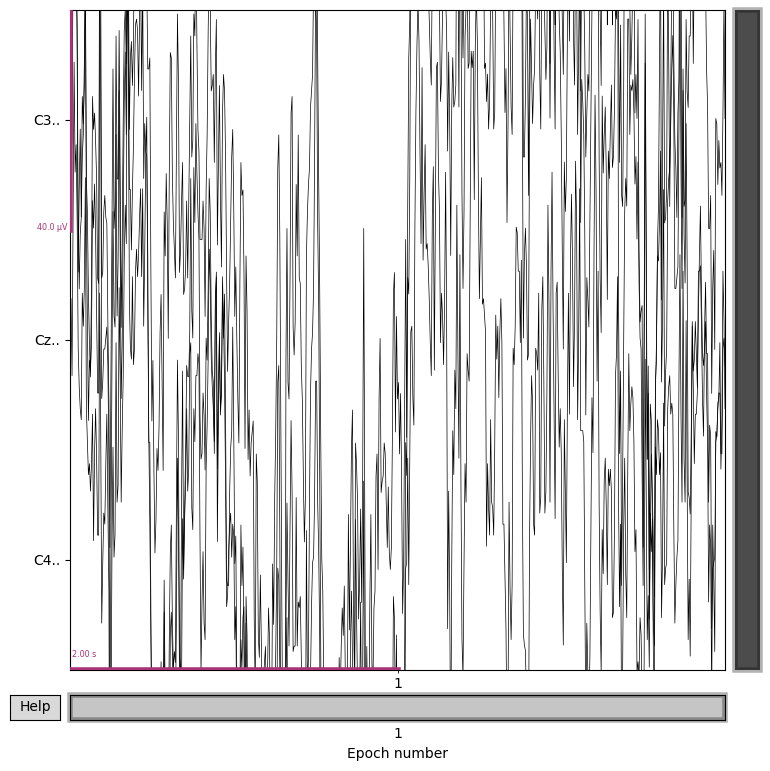

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


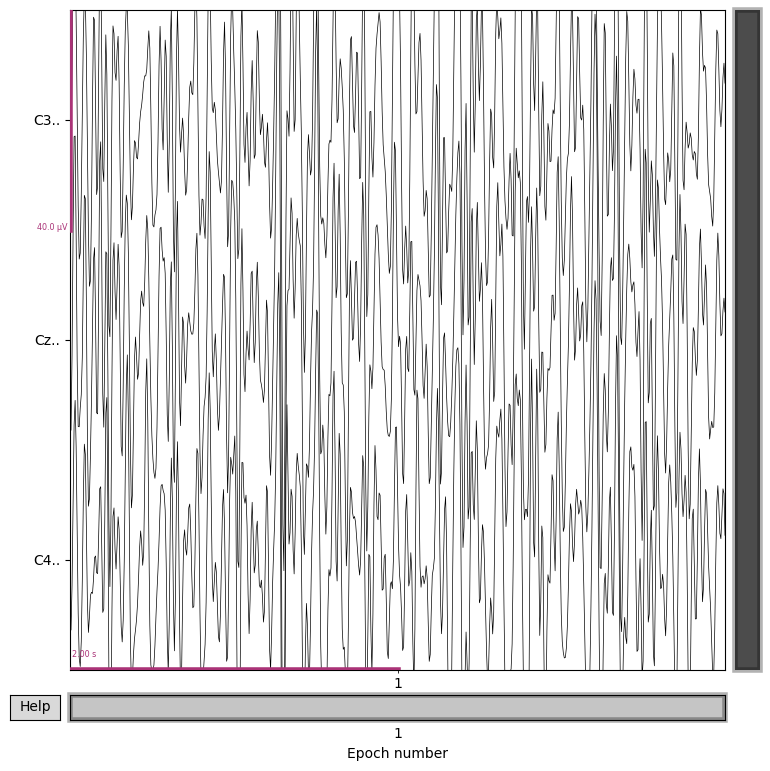

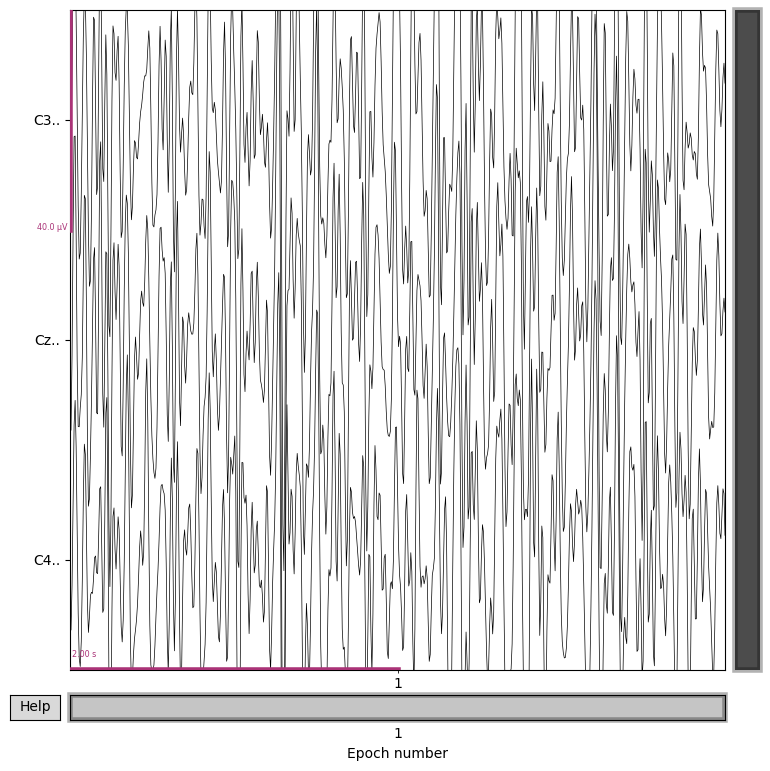

In [30]:
epochs[0].plot(
    picks=["C3..", "Cz..", "C4.."],
    title="Original EEG"
)

epochs_filtered[0].plot(
    picks=["C3..", "Cz..", "C4.."],
    title="Filtered EEG (8–30 Hz)"
)

In [31]:
epochs.ch_names

['Fc5.',
 'Fc3.',
 'Fc1.',
 'Fcz.',
 'Fc2.',
 'Fc4.',
 'Fc6.',
 'C5..',
 'C3..',
 'C1..',
 'Cz..',
 'C2..',
 'C4..',
 'C6..',
 'Cp5.',
 'Cp3.',
 'Cp1.',
 'Cpz.',
 'Cp2.',
 'Cp4.',
 'Cp6.',
 'Fp1.',
 'Fpz.',
 'Fp2.',
 'Af7.',
 'Af3.',
 'Afz.',
 'Af4.',
 'Af8.',
 'F7..',
 'F5..',
 'F3..',
 'F1..',
 'Fz..',
 'F2..',
 'F4..',
 'F6..',
 'F8..',
 'Ft7.',
 'Ft8.',
 'T7..',
 'T8..',
 'T9..',
 'T10.',
 'Tp7.',
 'Tp8.',
 'P7..',
 'P5..',
 'P3..',
 'P1..',
 'Pz..',
 'P2..',
 'P4..',
 'P6..',
 'P8..',
 'Po7.',
 'Po3.',
 'Poz.',
 'Po4.',
 'Po8.',
 'O1..',
 'Oz..',
 'O2..',
 'Iz..']

In [32]:
channels = ["C3..", "Cz..", "C4.."]
left_data=epochs["left"].get_data(picks=channels)
right_data=epochs["right"].get_data(picks=channels)
print("Left-hand imagery shape:", left_data.shape)
print("Right-hand imagery shape:", right_data.shape)

left_avg = left_data.mean(axis=0)
right_avg = right_data.mean(axis=0)

print("Left average shape:", left_avg.shape)
print("Right average shape:", right_avg.shape)

Left-hand imagery shape: (8, 3, 641)
Right-hand imagery shape: (7, 3, 641)
Left average shape: (3, 641)
Right average shape: (3, 641)


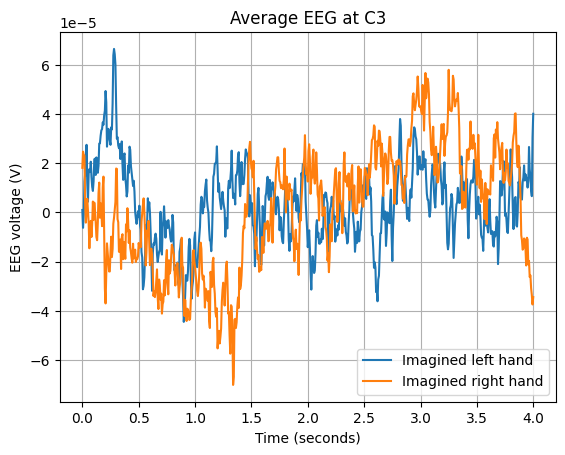

In [33]:
import matplotlib.pyplot as plt

plt.plot(epochs.times, left_avg[0], label="Imagined left hand")
plt.plot(epochs.times, right_avg[0], label="Imagined right hand")

plt.xlabel("Time (seconds)")
plt.ylabel("EEG voltage (V)")
plt.title("Average EEG at C3")
plt.legend()
plt.grid(True)
plt.show()

In [34]:
print("Left average min:", left_avg[0].min(), "V")
print("Left average max:", left_avg[0].max(), "V")

print("Right average min:", right_avg[0].min(), "V")
print("Right average max:", right_avg[0].max(), "V")

Left average min: -4.45e-05 V
Left average max: 6.65e-05 V
Right average min: -7.014285714285713e-05 V
Right average max: 5.8e-05 V


In [35]:
import numpy as np

# Get filtered EEG from C3 for each trial
left_c3 = epochs_filtered["left"].get_data(picks=["C3.."])[:, 0, :]
right_c3 = epochs_filtered["right"].get_data(picks=["C3.."])[:, 0, :]

# Mean squared amplitude as a simple band-power measure
left_power = np.mean(left_c3 ** 2, axis=1)
right_power = np.mean(right_c3 ** 2, axis=1)

print("Left trial powers:", left_power)
print("Right trial powers:", right_power)

print("Mean left power:", left_power.mean())
print("Mean right power:", right_power.mean())

Left trial powers: [3.28190915e-10 3.56321849e-10 4.11066677e-10 4.31363807e-10
 4.58492000e-10 4.01759110e-10 3.59319944e-10 5.32953968e-10]
Right trial powers: [3.65629506e-10 2.84904691e-10 2.71094049e-10 3.83801864e-10
 4.41009995e-10 3.89223748e-10 3.59758286e-10]
Mean left power: 4.099335337663566e-10
Mean right power: 3.564888771468668e-10


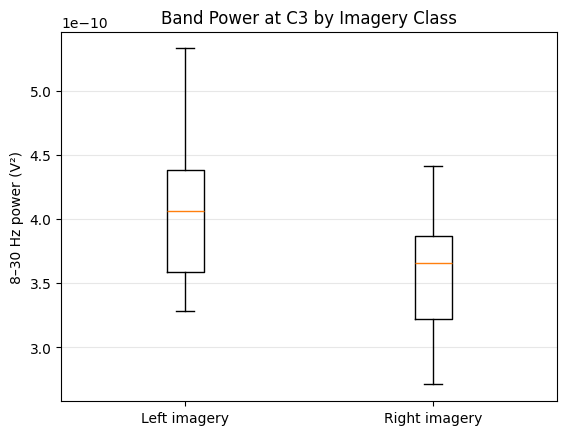

In [36]:
import matplotlib.pyplot as plt

plt.boxplot(
    [left_power, right_power],
    tick_labels=["Left imagery", "Right imagery"]
)

plt.ylabel("8–30 Hz power (V²)")
plt.title("Band Power at C3 by Imagery Class")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [37]:
import numpy as np

channels = ["C3..", "Cz..", "C4.."]

left_data = epochs_filtered["left"].get_data(picks=channels)
right_data = epochs_filtered["right"].get_data(picks=channels)

# Average squared amplitude across time
left_features = np.mean(left_data ** 2, axis=2)
right_features = np.mean(right_data ** 2, axis=2)

print("Left features:", left_features.shape)
print("Right features:", right_features.shape)

Left features: (8, 3)
Right features: (7, 3)


In [38]:
import numpy as np

# Combine trials into one feature matrix
X = np.vstack([left_features, right_features])

# Create labels: 0 = imagined left, 1 = imagined right
y = np.concatenate([
    np.zeros(len(left_features), dtype=int),
    np.ones(len(right_features), dtype=int)
])

print("Feature matrix shape:", X.shape)
print("Labels shape:", y.shape)
print("Labels:", y)

Feature matrix shape: (15, 3)
Labels shape: (15,)
Labels: [0 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.33,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train)
print("Testing labels:", y_test)

Training features: (10, 3)
Testing features: (5, 3)
Training labels: [0 1 1 0 1 1 0 0 0 1]
Testing labels: [1 0 0 1 0]


In [40]:
from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression()

# Learn from the training trials
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [42]:
y_pred = model.predict(X_test)

print("Actual labels:   ", y_test)
print("Predicted labels:", y_pred)

Actual labels:    [1 0 0 1 0]
Predicted labels: [0 0 0 0 0]


In [43]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {accuracy:.2%}")

Test accuracy: 60.00%
